# K-Means em duas passadas + métricas (Parte Comum)

Implementação em `src/parte_comum/kmeans.py` e `src/parte_comum/metricas.py`. O K-Means **não vê** `quality` nem `tipo`: os rótulos reais só são usados *depois*, para medir a coincidência entre grupos e classes.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[1] / "src" / "parte_comum"))  # notebooks/parte_comum -> src/parte_comum
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Image
from common import *
estilo_graficos()
pd.set_option("display.width", 200, "display.max_columns", 30)
%matplotlib inline
import kmeans as K, metricas as M
res = K.experimento('ambos', 'nenhum', salvar_saidas=False)
df, X = res['df'], res['X']
p1, p2 = res['passada1'], res['passada2']

## 1. Padronização (z-score)

O K-Means minimiza distâncias **euclidianas**: variáveis com escala/variância grande dominam a distância. Aqui o SO₂ total (variância ≈ 3 200) pesa ~10⁸ vezes mais que a densidade (≈ 9·10⁻⁶). Sem padronizar, praticamente só SO₂ determina os grupos:

ARI sem padronizar: 0.0024 | com padronização: 0.0353


,% da separação entre centroides (dados brutos)
total_sulfur_dioxide,94.64
free_sulfur_dioxide,5.16
residual_sugar,0.18
fixed_acidity,0.01
alcohol,0.01
volatile_acidity,0.00
sulphates,0.00
ph,0.00
citric_acid,0.00
chlorides,0.00


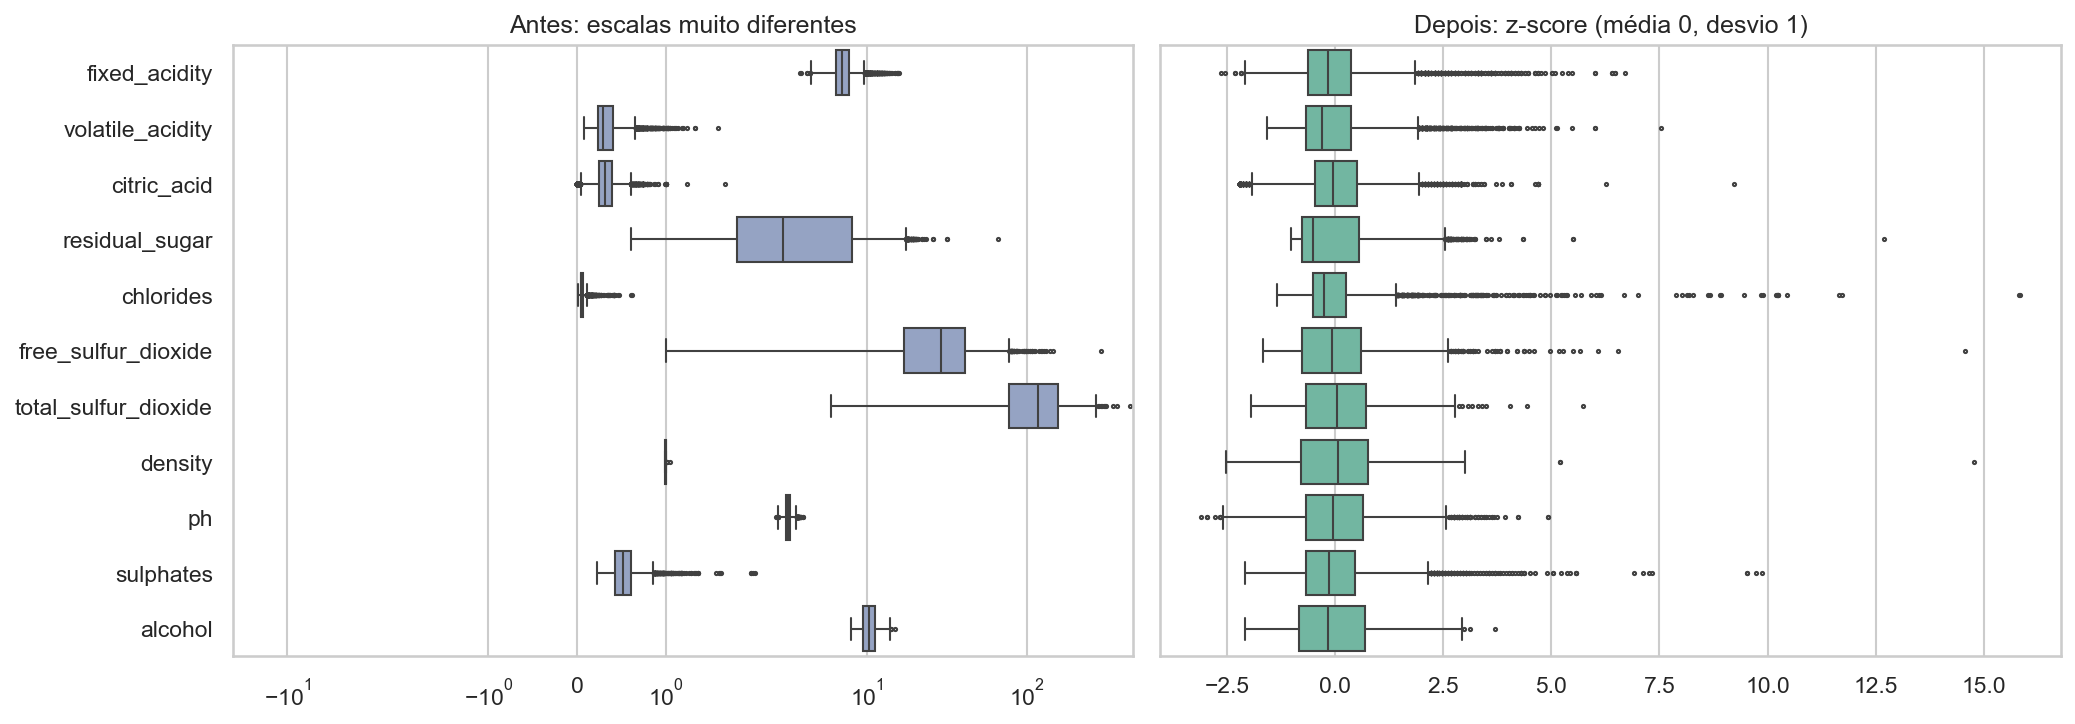

In [2]:
bruto = K.sem_padronizar_para_comparacao(df, 7)
print('ARI sem padronizar: %.4f | com padronização: %.4f' % (bruto['ARI'], p2['resumo']['ARI']))
display(bruto['contribuicao_pct'].round(2).rename('% da separação entre centroides (dados brutos)').to_frame())
display(Image(filename=str(OUT_DIR / "kmeans/padronizacao_antes_depois.png")))

## 2. Passada 1 — k livre (Método do Cotovelo)

,inercia,silhouette
k,,
2,56143.929,0.277
3,45577.000,0.237
4,40721.014,0.249
5,38069.169,0.181
6,35806.739,0.189
7,34024.978,0.182
8,32708.623,0.161
9,31592.017,0.147
10,30557.746,0.147


k sugerido pelo cotovelo = 4


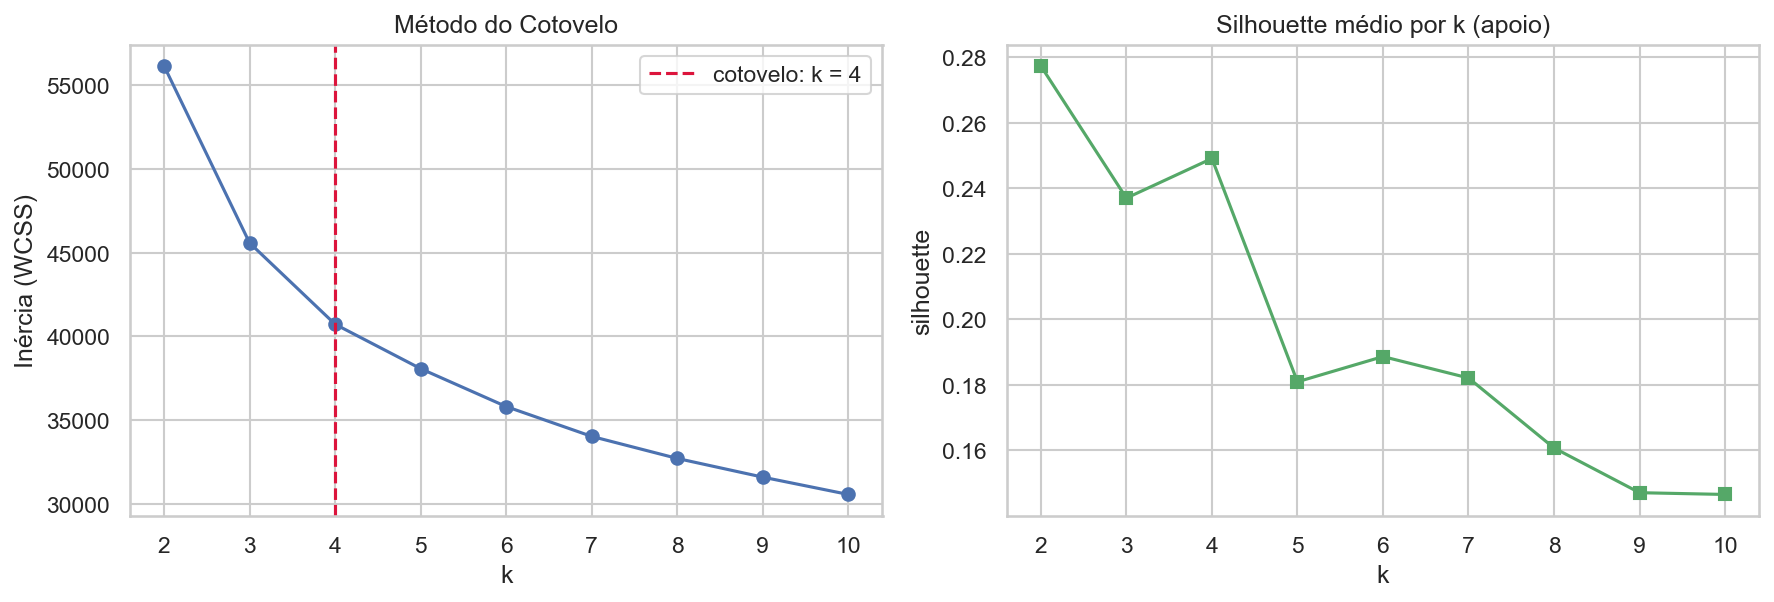

In [3]:
display(res['varredura'].round(3))
print('k sugerido pelo cotovelo =', p1['resumo']['k'])
display(Image(filename=str(OUT_DIR / "kmeans/passada1_cotovelo.png")))

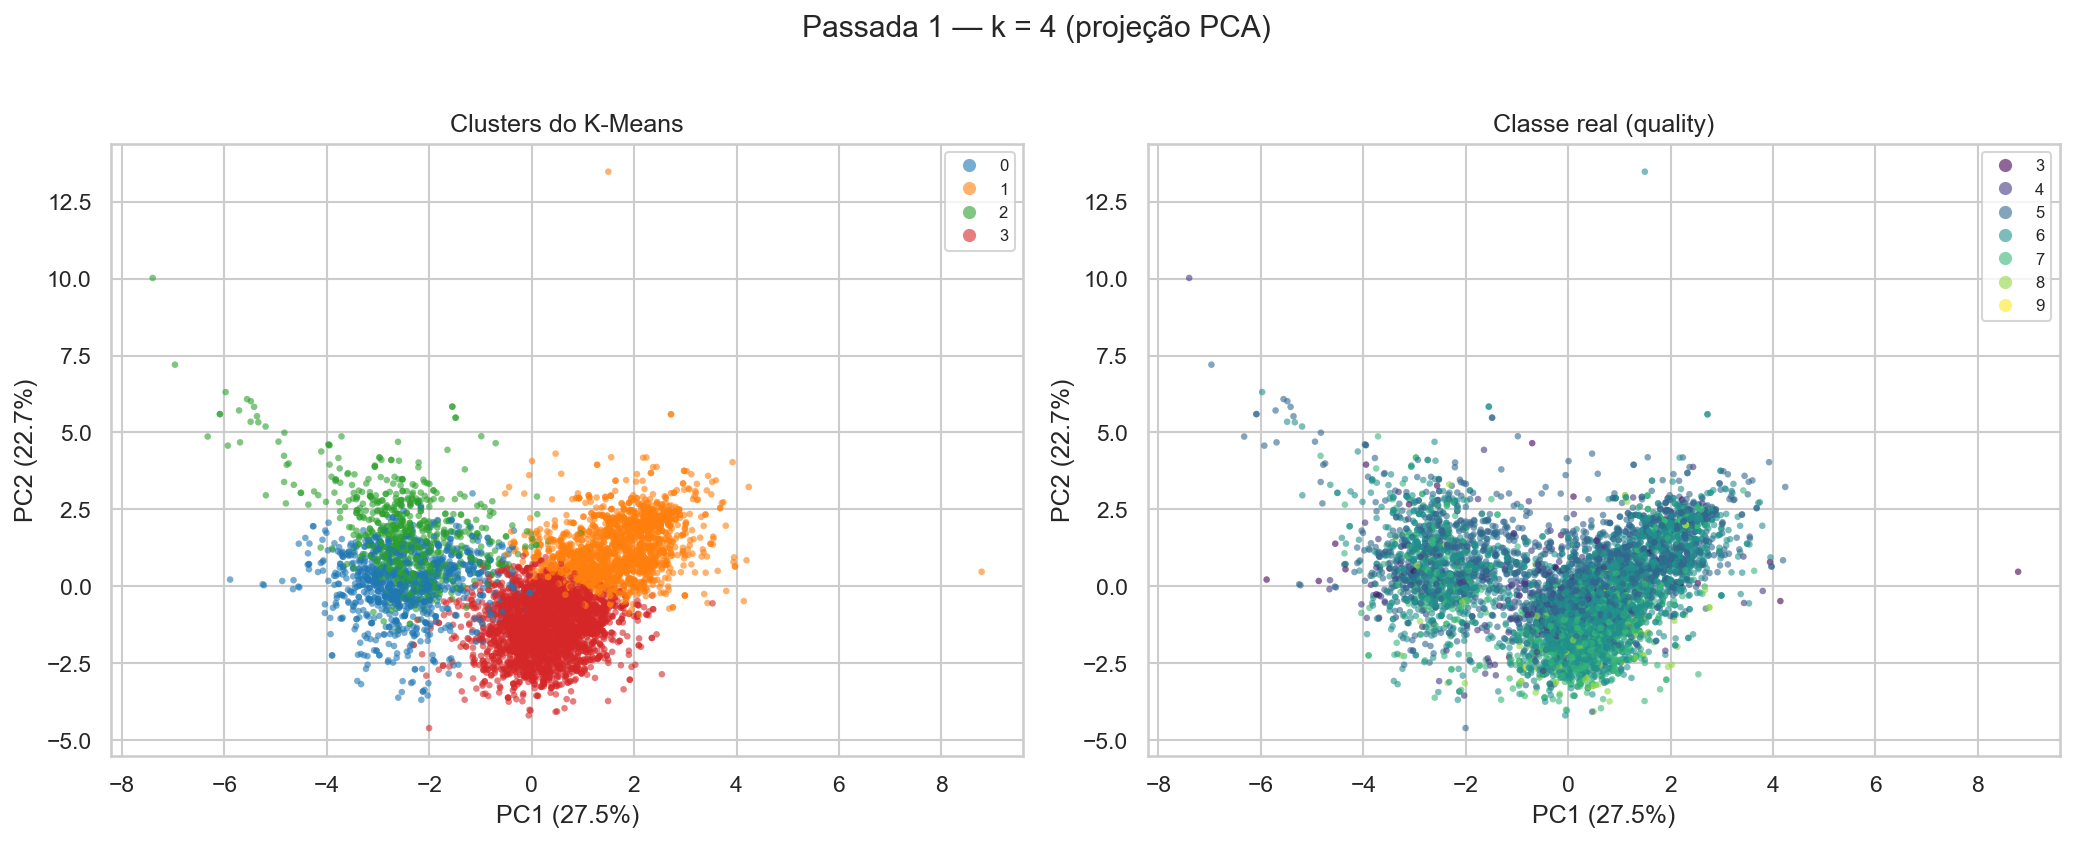

In [4]:
display(Image(filename=str(OUT_DIR / "kmeans/passada1_pca.png")))

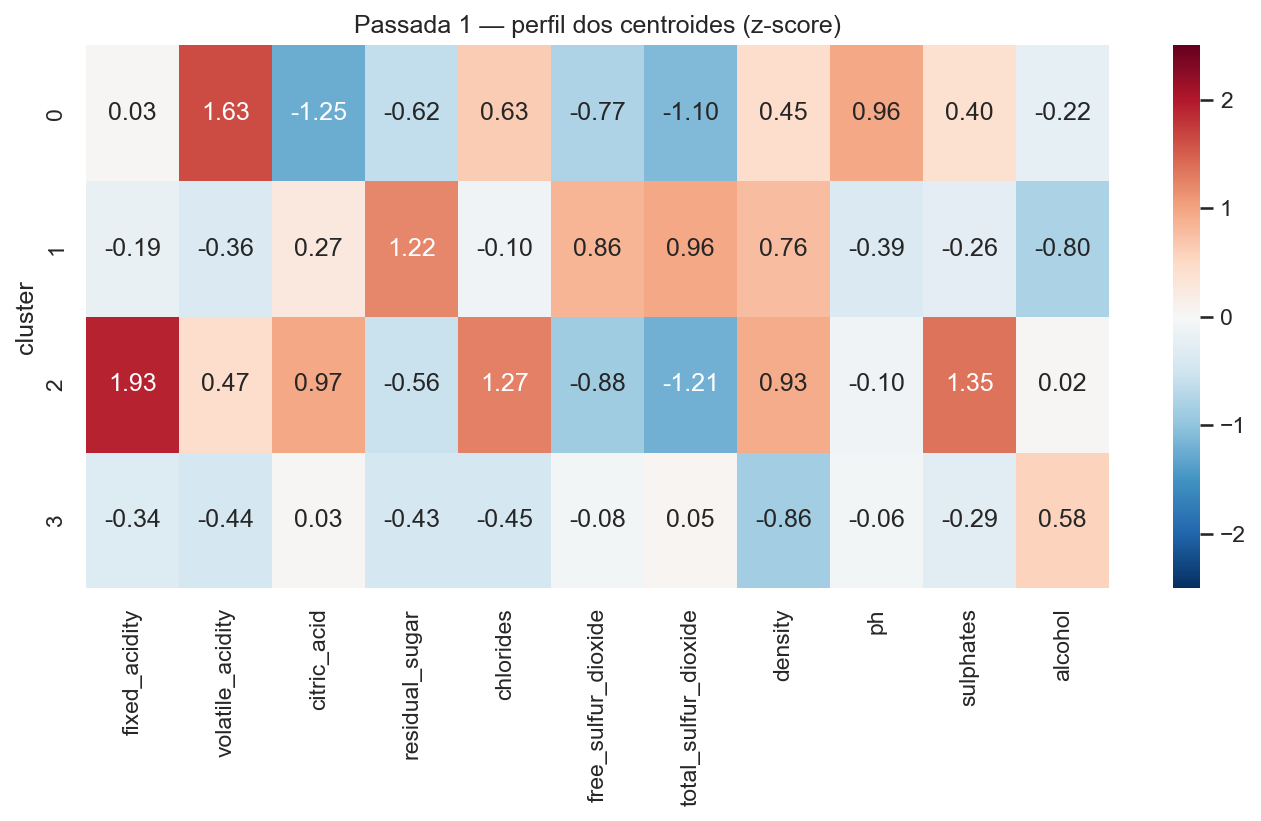

In [5]:
display(Image(filename=str(OUT_DIR / "kmeans/passada1_perfil_centroides.png")))

O cotovelo (distância máxima à reta que une k=2 e k=10) aponta **k = 4**; o silhouette é maior em k=2 e tem um segundo pico em k=4. Nenhum desses k é 7, o que já indica que a estrutura natural dos dados **não** corresponde às 7 notas.

### Métricas — Passada 1

Mapa cluster→classe: {0: 5, 1: 6, 2: 6, 3: 6}

Matriz de confusão RETANGULAR (classe real × cluster→classe mapeada):


,C0→5,C1→6,C2→6,C3→6
classe_real,,,,
3,7,10,5,8
4,71,44,20,81
5,503,797,229,609
6,366,833,285,1352
7,53,157,136,733
8,6,31,12,144
9,0,1,0,4


Matriz de confusão QUADRADA (real × rótulo mapeado):


mapeado,3,4,5,6,7,8,9
classe,,,,,,,
3,0,0,7,23,0,0,0
4,0,0,71,145,0,0,0
5,0,0,503,1635,0,0,0
6,0,0,366,2470,0,0,0
7,0,0,53,1026,0,0,0
8,0,0,6,187,0,0,0
9,0,0,0,5,0,0,0


,suporte,TP,FP,FN,TN,acuracia_ovr,precisao,recall,f1
classe,,,,,,,,,
3,30,0,0,30,6467,0.995,NaN,0.000,0.000
4,216,0,0,216,6281,0.967,NaN,0.000,0.000
5,2138,503,503,1635,3856,0.671,0.50,0.235,0.320
6,2836,2470,3021,366,640,0.479,0.45,0.871,0.593
7,1079,0,0,1079,5418,0.834,NaN,0.000,0.000
8,193,0,0,193,6304,0.970,NaN,0.000,0.000
9,5,0,0,5,6492,0.999,NaN,0.000,0.000


{'acuracia_global': 0.4576, 'precisao_macro': 0.1357, 'recall_macro': 0.158, 'f1_macro': 0.1305, 'classes_nunca_previstas': [3, 4, 7, 8, 9], 'silhouette': 0.2491, 'ARI': 0.022, 'NMI': 0.0448, 'homogeneidade': 0.0442}
Baseline (sempre prever a classe majoritária): 0.4365


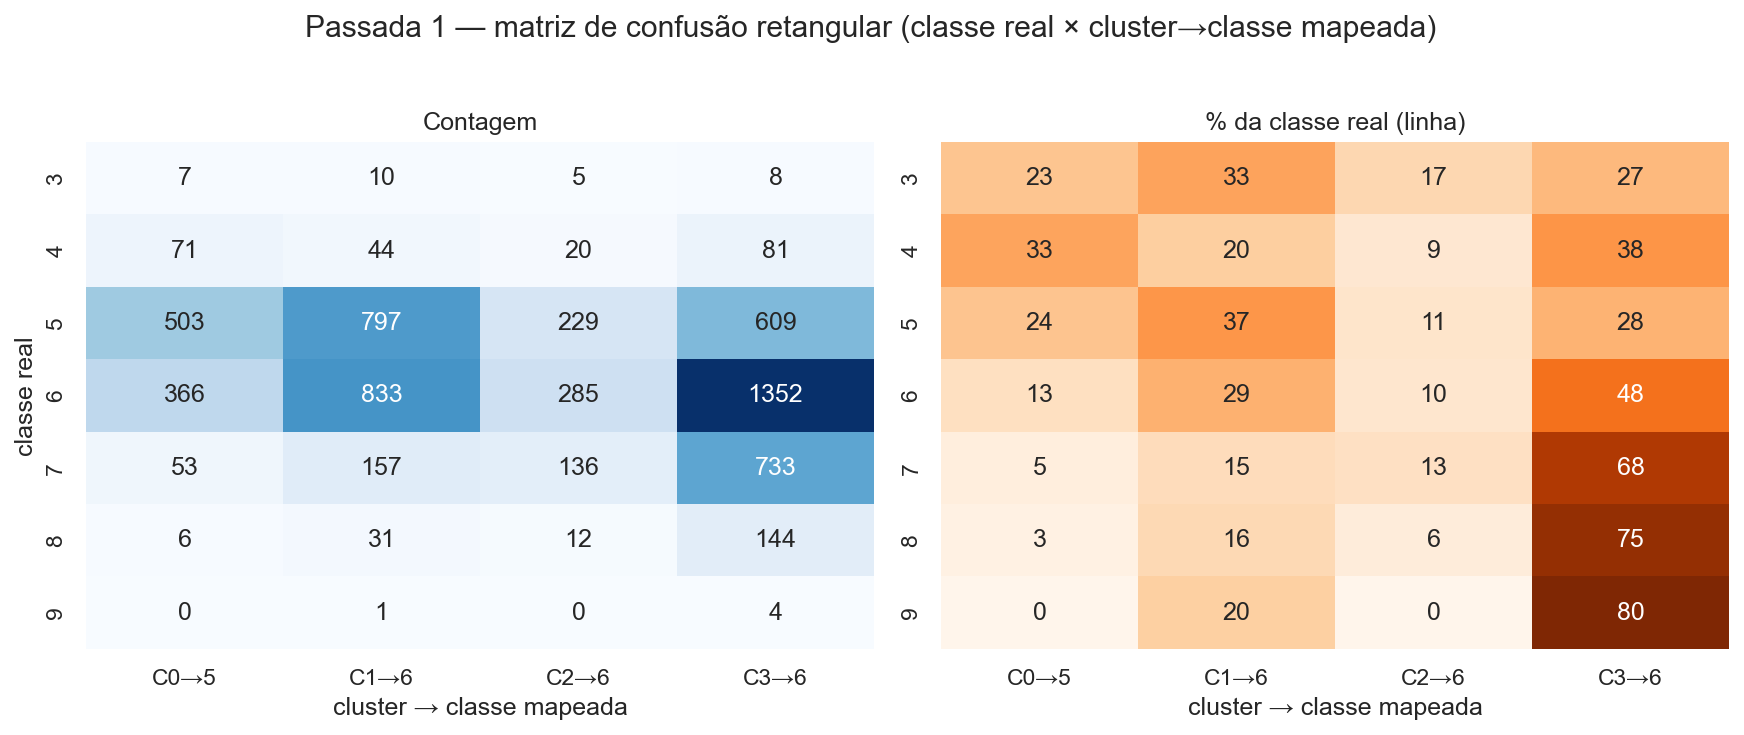

In [6]:
a = p1['av']
print('Mapa cluster→classe:', a['mapa'])
print('\nMatriz de confusão RETANGULAR (classe real × cluster→classe mapeada):'); display(a['contingencia'])
print('Matriz de confusão QUADRADA (real × rótulo mapeado):'); display(a['confusao'])
display(a['por_classe'].round(3))
print({k: (round(v,4) if isinstance(v,float) else v) for k,v in {**a['global'], **a['nao_supervisionadas']}.items()})
print('Baseline (sempre prever a classe majoritária): %.4f' % a['baseline_classe_majoritaria'])
display(Image(filename=str(OUT_DIR / "kmeans/passada1_matriz_retangular.png")))

## 3. Passada 2 — k fixo = 7 (nº de classes)

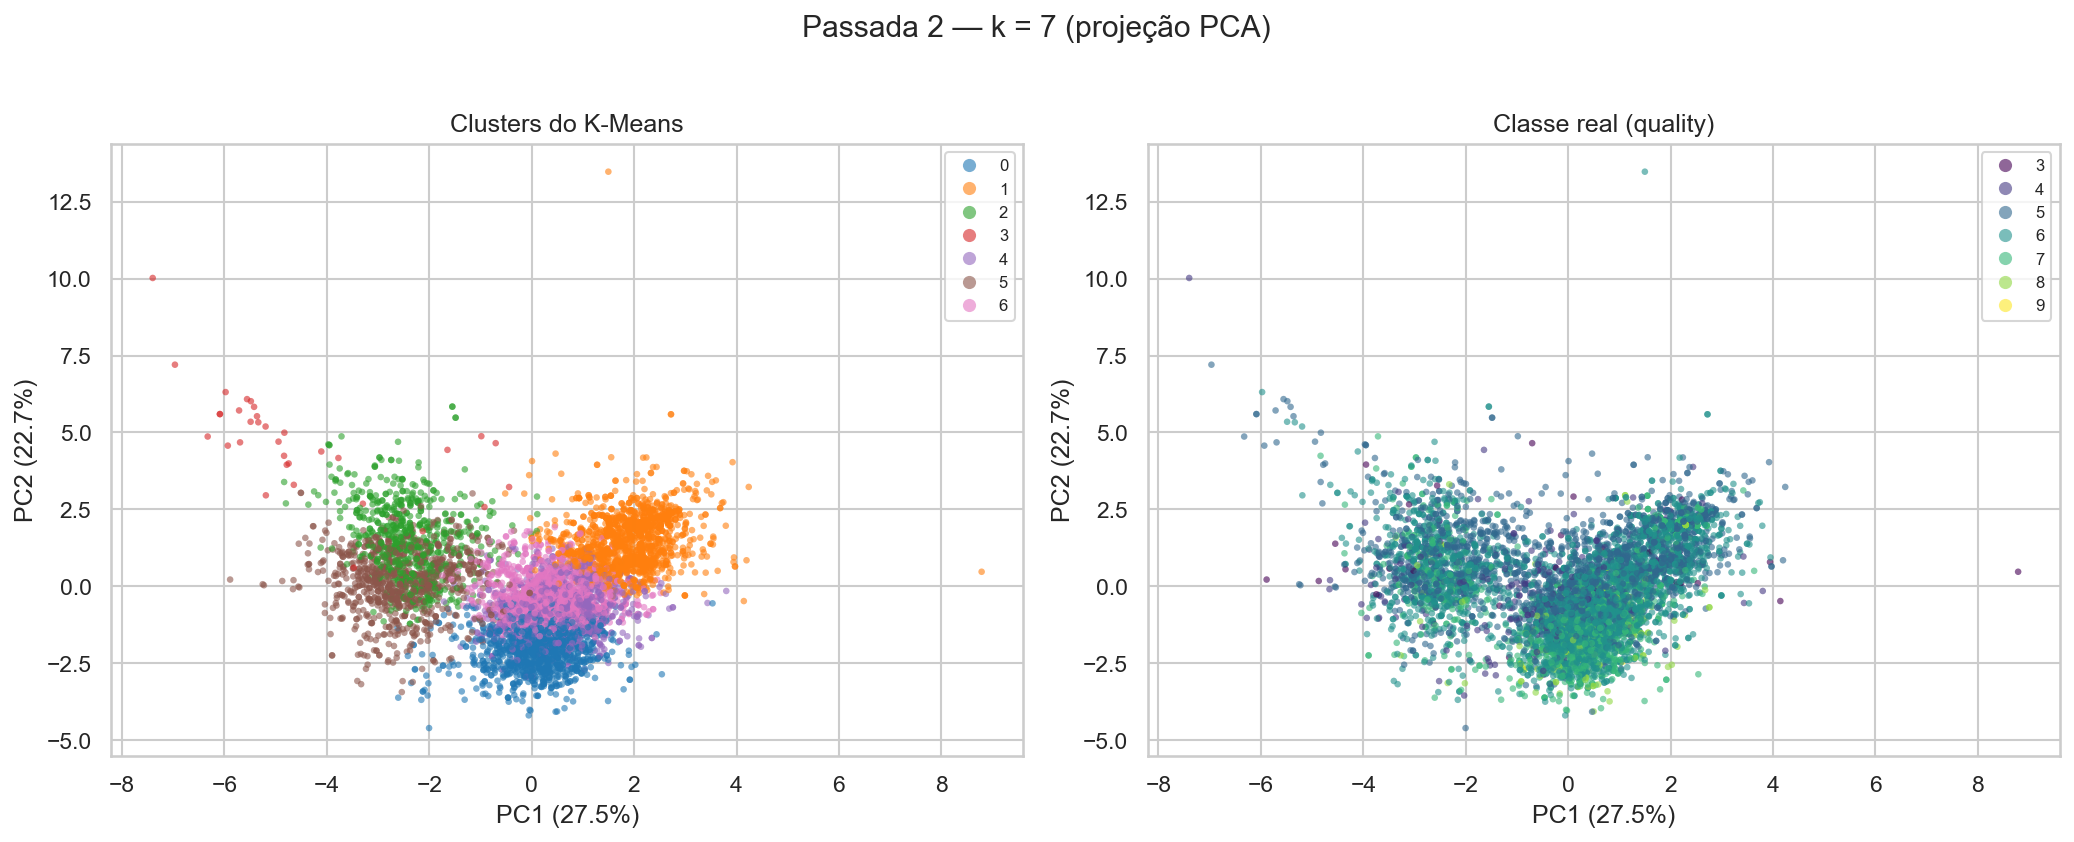

In [7]:
display(Image(filename=str(OUT_DIR / "kmeans/passada2_pca.png")))

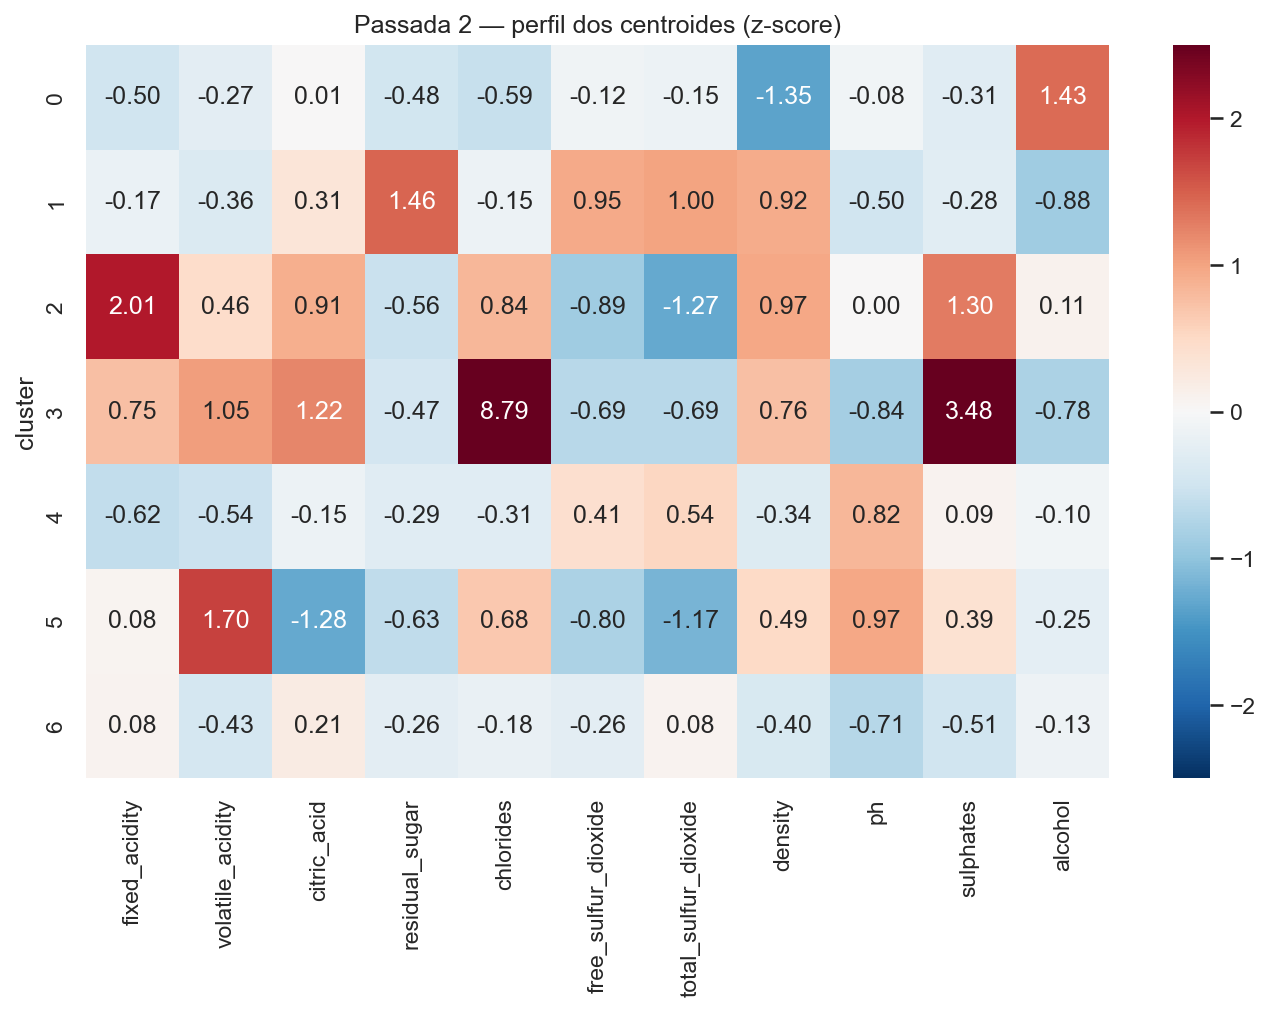

In [8]:
display(Image(filename=str(OUT_DIR / "kmeans/passada2_perfil_centroides.png")))

Mapa cluster→classe: {0: 6, 1: 5, 2: 6, 3: 5, 4: 6, 5: 5, 6: 6}

Matriz de confusão RETANGULAR (7 classes × 7 clusters):


,C1→5,C3→5,C5→5,C0→6,C2→6,C4→6,C6→6
classe_real,,,,,,,
3,7,1,7,3,4,3,5
4,24,2,63,23,15,26,63
5,652,20,470,76,200,263,457
6,640,9,350,558,266,480,533
7,122,1,43,450,141,191,131
8,22,0,2,98,14,32,25
9,0,0,0,4,0,0,1


Matriz de confusão QUADRADA (real × rótulo mapeado):


mapeado,3,4,5,6,7,8,9
classe,,,,,,,
3,0,0,15,15,0,0,0
4,0,0,89,127,0,0,0
5,0,0,1142,996,0,0,0
6,0,0,999,1837,0,0,0
7,0,0,166,913,0,0,0
8,0,0,24,169,0,0,0
9,0,0,0,5,0,0,0


,suporte,TP,FP,FN,TN,acuracia_ovr,precisao,recall,f1
classe,,,,,,,,,
3,30,0,0,30,6467,0.995,NaN,0.000,0.000
4,216,0,0,216,6281,0.967,NaN,0.000,0.000
5,2138,1142,1293,996,3066,0.648,0.469,0.534,0.499
6,2836,1837,2225,999,1436,0.504,0.452,0.648,0.533
7,1079,0,0,1079,5418,0.834,NaN,0.000,0.000
8,193,0,0,193,6304,0.970,NaN,0.000,0.000
9,5,0,0,5,6492,0.999,NaN,0.000,0.000


{'acuracia_global': 0.4585, 'precisao_macro': 0.1316, 'recall_macro': 0.1688, 'f1_macro': 0.1474, 'classes_nunca_previstas': [3, 4, 7, 8, 9], 'silhouette': 0.1821, 'ARI': 0.0353, 'NMI': 0.0627, 'homogeneidade': 0.0753}
Baseline: 0.4365


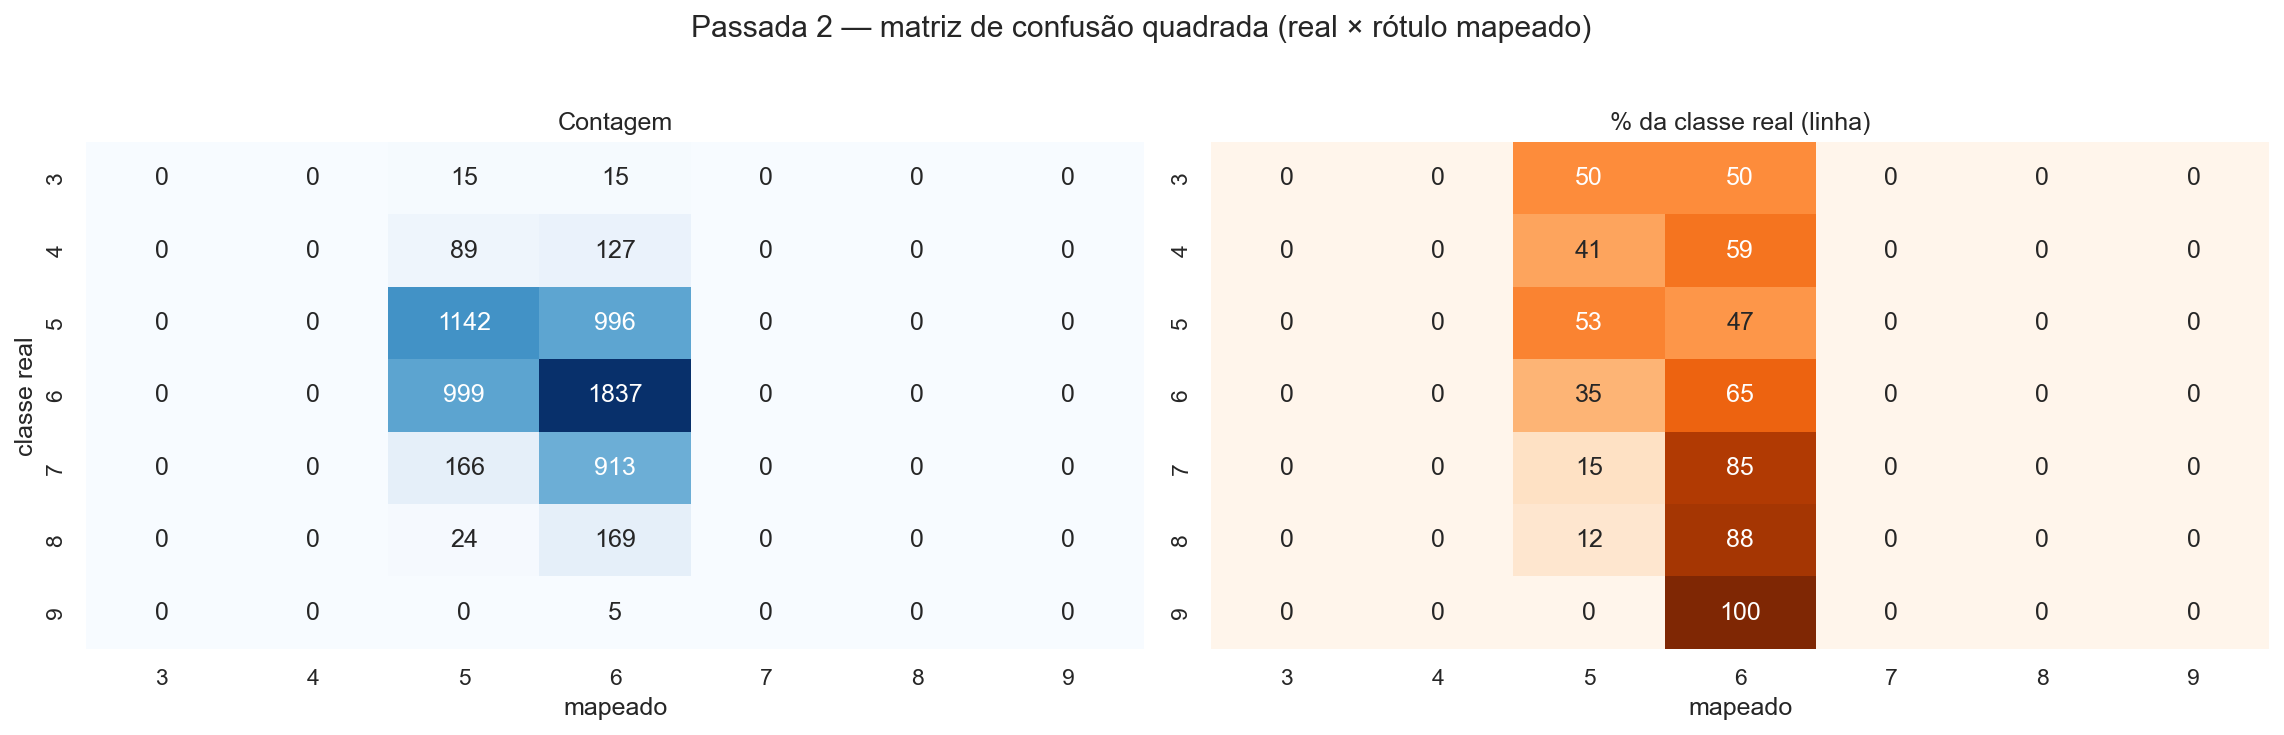

In [9]:
a = p2['av']
print('Mapa cluster→classe:', a['mapa'])
print('\nMatriz de confusão RETANGULAR (7 classes × 7 clusters):'); display(a['contingencia'])
print('Matriz de confusão QUADRADA (real × rótulo mapeado):'); display(a['confusao'])
display(a['por_classe'].round(3))
print({k: (round(v,4) if isinstance(v,float) else v) for k,v in {**a['global'], **a['nao_supervisionadas']}.items()})
print('Baseline: %.4f' % a['baseline_classe_majoritaria'])
display(Image(filename=str(OUT_DIR / "kmeans/passada2_matriz_confusao.png")))

In [10]:
print('Cluster × tipo de vinho (Passada 2):')
display(pd.crosstab(p2['km'].labels_, df['tipo'].values, rownames=['cluster']))

Cluster × tipo de vinho (Passada 2):


col_0,branco,tinto
cluster,,
0,1180,32
1,1465,2
2,16,624
3,6,27
4,976,19
5,50,885
6,1205,10


## 4. Comparação das passadas e sensibilidade

In [11]:
comp = pd.DataFrame({'Passada 1 (k=%d)' % p1['resumo']['k']: p1['resumo'], 'Passada 2 (k=7)': p2['resumo']}).drop(['mapa_cluster_para_classe','classes_nunca_previstas'])
display(comp.round(4))
sens = pd.read_csv(OUT_DIR / 'kmeans' / 'sensibilidade_cenarios.csv')
display(sens.round(3))

,Passada 1 (k=4),Passada 2 (k=7)
k,4,7
inercia,40721.014237,34024.977867
acuracia_global,0.457596,0.458519
precisao_macro,0.13569,0.131605
recall_macro,0.15803,0.168841
f1_macro,0.130461,0.147439
silhouette,0.249148,0.182117
ARI,0.022027,0.035277
NMI,0.04476,0.062723
homogeneidade,0.044239,0.075293


,cenario,passada,n,n_classes,k,acuracia,baseline_maioria,precisao_macro,recall_macro,silhouette,ARI,NMI
0,"tinto+branco, sem tratamento (PRINCIPAL)",1,6497,7,4,0.458,0.437,0.136,0.158,0.249,0.022,0.045
1,"tinto+branco, sem tratamento (PRINCIPAL)",2,6497,7,7,0.459,0.437,0.132,0.169,0.182,0.035,0.063
2,"tinto+branco, winsorizado 1–99%",1,6497,7,4,0.458,0.437,0.136,0.158,0.254,0.023,0.047
3,"tinto+branco, winsorizado 1–99%",2,6497,7,7,0.459,0.437,0.132,0.170,0.184,0.032,0.060
4,somente tinto,1,1599,6,5,0.552,0.426,0.182,0.222,0.190,0.065,0.095
5,somente tinto,2,1599,6,6,0.550,0.426,0.181,0.221,0.195,0.062,0.093
6,somente branco,1,4898,7,5,0.455,0.449,0.130,0.169,0.144,0.038,0.052
7,somente branco,2,4898,7,7,0.479,0.449,0.138,0.174,0.126,0.034,0.071


**Conclusões.**
- As duas passadas têm acurácia de ~45,8 %, **praticamente igual ao baseline de 43,7 %** (chutar sempre 'nota 6'). ARI ≈ 0,02–0,04 e NMI ≈ 0,04–0,06: os grupos quase não coincidem com as notas.
- Os clusters refletem sobretudo **tipo de vinho** (tinto × branco) e perfis químicos (alto álcool, alta acidez, alto açúcar), não qualidade. O único sinal de qualidade é o cluster de **álcool alto (~12,2 %)**: concentra 42 % dos vinhos nota 7, 51 % da nota 8 e 4 dos 5 vinhos nota 9 (nota média 6,43 vs. 5,2–5,9 nos demais clusters).
- Só as classes 5 e 6 são 'mapeadas'; 3, 4, 7, 8 e 9 **nunca são majoritárias** em nenhum cluster (recall 0, precisão indefinida). A acurácia por classe (um-contra-todos) dessas classes parece alta (≥ 0,83) apenas porque o modelo 'acerta' dizendo que o vinho não pertence a elas — por isso precisão e recall são mais informativos.
- A sensibilidade (winsorização, só tinto, só branco) não altera a conclusão.